In [2]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np


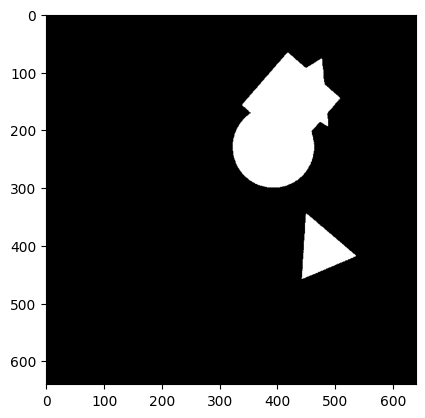

In [30]:
image = cv.imread(r"C:\Users\Omar-PC\OneDrive - El Sewedy Education\Desktop\shape_color_sorting\Dataset\images\train\synthetic_1.jpg")
image.shape
image_hsv=cv.cvtColor(image,cv.COLOR_BGR2HSV)

lower_blue = np.array([100, 150, 20])
upper_blue = np.array([140, 255, 255])
mask_blue = cv.inRange(image_hsv, lower_blue, upper_blue)

lower_red1=np.array([0,100,20])
upper_red1=np.array([10,255,255])
mask_red1=cv.inRange(image_hsv,lower_red1,upper_red1)
lower_red2=np.array([170,100,20])
upper_red2=np.array([179,255,255])
mask_red2=cv.inRange(image_hsv,lower_red2,upper_red2)

mask_red=cv.bitwise_or(mask_red1,mask_red2)

red_blue_mask = cv.bitwise_or(mask_blue, mask_red)
lower_green=np.array([35,100,20])
upper_green=np.array([85,255,255])

mask_green=cv.inRange(image_hsv,lower_green,upper_green)
final_mask=cv.bitwise_or(red_blue_mask,mask_green)
# Display the result
plt.imshow(final_mask, cmap='gray')
plt.show()


Found 0 Red object(s).
Found 0 Blue object(s).
Found 2 Green object(s).
the total number is 2


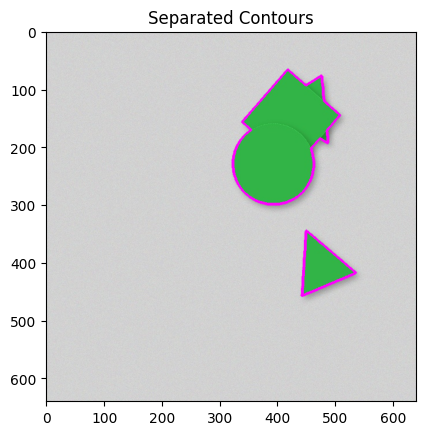

In [31]:
color_masks={
    "Red":mask_red,
    "Blue":mask_blue,
    "Green":mask_green
}

image_with_contours=image.copy()
total_objects= 0
for color_name,specific_mask in color_masks.items():
    contours,hierarchies=cv.findContours(specific_mask,cv.RETR_EXTERNAL,cv.CHAIN_APPROX_SIMPLE)
    print(f"Found {len(contours)} {color_name} object(s).")
    total_objects +=len(contours)
    cv.drawContours(image_with_contours,contours,-1,(255,0,255),3)

print(f"the total number is {total_objects}")
plt.imshow(cv.cvtColor(image_with_contours, cv.COLOR_BGR2RGB))
plt.title("Separated Contours")
plt.show()

   

In [ ]:
for color_name, specific_mask in color_masks.items():
    contours, hierarchies = cv.findContours(specific_mask, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)
    
    for contour in contours:

        area = cv.contourArea(contour)
        print(f"{color_name} counter area {area}")
        if area < 300:
            continue
            
        perimeter = cv.arcLength(contour, True)
        epsilon = 0.04 * perimeter 
        approx = cv.approxPolyDP(contour, epsilon, True)
        corners = len(approx)
        
        # Determine the shape name based on corner count
        if corners == 3:
            shape_name = "Triangle"
        elif corners == 4:
            shape_name = "Square"
        else:
            shape_name = "Circle"
            
        M = cv.moments(contour)
        if M["m00"] != 0:
            cx = int(M["m10"] / M["m00"])
            cy = int(M["m01"] / M["m00"])
        else:
            cx, cy = 0, 0
            
        print(f"Detected: {color_name} {shape_name} at coordinates ({cx}, {cy})")
        
        cv.drawContours(image_with_contours, [approx], -1, (0, 255, 0), 3)
        cv.putText(image_with_contours, f"{color_name} {shape_name}", (cx - 40, cy - 10), 
                   cv.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 2)

Red counter area 8188.5
Detected: Red Triangle at coordinates (183, 502)
Blue counter area 8555.5
Detected: Blue Triangle at coordinates (357, 162)
Green counter area 3310.5
Detected: Green Triangle at coordinates (324, 481)
Green counter area 11406.0
Detected: Green Square at coordinates (455, 241)


In [8]:
from pathlib import Path

train_dir = Path(
    r"C:\Users\Omar-PC\OneDrive - El Sewedy Education\Desktop\shape_color_sorting\Dataset\images\train"
)

image_files = sorted([
    file for file in train_dir.iterdir()
    if file.suffix.lower() in [".jpg", ".jpeg", ".png"]
])

print("Number of training images:", len(image_files))

Number of training images: 850


In [ ]:
def detect_objects(image, area_threshold=300):

    image_hsv = cv.cvtColor(image, cv.COLOR_BGR2HSV)

    lower_blue = np.array([100, 150, 20])
    upper_blue = np.array([140, 255, 255])

    mask_blue = cv.inRange(
        image_hsv,
        lower_blue,
        upper_blue
    )


    # --------------------------------
    # RED MASK
    # --------------------------------
    lower_red1 = np.array([0, 100, 20])
    upper_red1 = np.array([10, 255, 255])

    mask_red1 = cv.inRange(
        image_hsv,
        lower_red1,
        upper_red1
    )

    lower_red2 = np.array([170, 100, 20])
    upper_red2 = np.array([179, 255, 255])

    mask_red2 = cv.inRange(
        image_hsv,
        lower_red2,
        upper_red2
    )

    mask_red = cv.bitwise_or(
        mask_red1,
        mask_red2
    )


    # --------------------------------
    # GREEN MASK
    # --------------------------------
    lower_green = np.array([35, 100, 20])
    upper_green = np.array([85, 255, 255])

    mask_green = cv.inRange(
        image_hsv,
        lower_green,
        upper_green
    )



    color_masks = {
        "Red": mask_red,
        "Blue": mask_blue,
        "Green": mask_green
    }


    image_with_contours = image.copy()

    detections = []


    for color_name, specific_mask in color_masks.items():

        contours, _ = cv.findContours(
            specific_mask,
            cv.RETR_EXTERNAL,
            cv.CHAIN_APPROX_SIMPLE
        )


        for contour in contours:

            
            area = cv.contourArea(contour)

            if area < area_threshold:
                continue


            perimeter = cv.arcLength(
                contour,
                True
            )

            epsilon = 0.04 * perimeter

            approx = cv.approxPolyDP(
                contour,
                epsilon,
                True
            )

            corners = len(approx)


            if corners == 3:
                shape_name = "Triangle"

            elif corners == 4:
                shape_name = "Square"

            else:
                shape_name = "Circle"

            M = cv.moments(contour)

            if M["m00"] == 0:
                continue

            cx = int(M["m10"] / M["m00"])
            cy = int(M["m01"] / M["m00"])


              
    
            detections.append({
                "color": color_name,
                "shape": shape_name,
                "x": cx,
                "y": cy,
                "area": area
            })

            cv.drawContours(
                image_with_contours,
                [approx],
                -1,
                (0, 255, 0),
                3
            )

            cv.putText(
                image_with_contours,
                f"{color_name} {shape_name}",
                (cx - 40, cy - 10),
                cv.FONT_HERSHEY_SIMPLEX,
                0.5,
                (255, 255, 255),
                2
            )


    return detections, image_with_contours

In [10]:
total_images = 0
total_objects = 0
failed_images = []

for image_path in image_files:

    image = cv.imread(str(image_path))

    if image is None:
        failed_images.append(image_path.name)
        continue


    detections, result = detect_objects(image)

    total_images += 1
    total_objects += len(detections)


    print("\n----------------------------")
    print("Image:", image_path.name)
    print("Objects detected:", len(detections))


    for detection in detections:

        print(
            f"  {detection['color']} "
            f"{detection['shape']} "
            f"at ({detection['x']}, {detection['y']}) "
            f"area={detection['area']:.1f}"
        )


print("\n============================")
print("TRAINING DATASET SUMMARY")
print("============================")

print("Images processed:", total_images)
print("Objects detected:", total_objects)
print("Failed images:", len(failed_images))


----------------------------
Image: synthetic_0.jpg
Objects detected: 3
  Red Square at (440, 298) area=11358.0
  Blue Square at (322, 421) area=15253.0
  Blue Circle at (554, 286) area=4967.5

----------------------------
Image: synthetic_1.jpg
Objects detected: 2
  Green Triangle at (476, 406) area=5149.5
  Green Circle at (408, 189) area=26606.0

----------------------------
Image: synthetic_10.jpg
Objects detected: 3
  Red Triangle at (249, 561) area=2875.5
  Red Square at (387, 121) area=6432.0
  Green Circle at (203, 466) area=12042.0

----------------------------
Image: synthetic_100.jpg
Objects detected: 4
  Red Square at (102, 167) area=10076.0
  Red Circle at (301, 116) area=4313.0
  Red Triangle at (417, 104) area=6258.0
  Green Circle at (140, 350) area=13638.0

----------------------------
Image: synthetic_101.jpg
Objects detected: 2
  Red Circle at (419, 499) area=4314.5
  Green Triangle at (471, 197) area=2837.5

----------------------------
Image: synthetic_102.jpg
Obj

In [ ]:
from pathlib import Path

labels_dir = Path(
    r"C:\Users\Omar-PC\OneDrive - El Sewedy Education\Desktop\shape_color_sorting\Dataset\labels\train"
)

correct_count_images = 0
wrong_count_images = []

for image_path in image_files:

    image = cv.imread(str(image_path))

    if image is None:
        continue

    detections, _ = detect_objects(image)

    predicted_count = len(detections)


    label_path = labels_dir / f"{image_path.stem}.txt"

    if not label_path.exists():
        print("Missing label:", label_path.name)
        continue


    # Each non-empty line = one real object
    with open(label_path, "r") as f:
        lines = [
            line for line in f.readlines()
            if line.strip()
        ]

    actual_count = len(lines)


    if predicted_count == actual_count:
        correct_count_images += 1

    else:
        wrong_count_images.append({
            "image": image_path.name,
            "predicted": predicted_count,
            "actual": actual_count
        })


print("\n============================")
print("OBJECT COUNT CHECK")
print("============================")

print("Total images:", len(image_files))
print("Correct object count:", correct_count_images)
print("Wrong object count:", len(wrong_count_images))

accuracy = correct_count_images / len(image_files) * 100

print(f"Count accuracy: {accuracy:.2f}%")


OBJECT COUNT CHECK
Total images: 850
Correct object count: 626
Wrong object count: 224
Count accuracy: 73.65%


In [12]:
under_detected = []
over_detected = []

for item in wrong_count_images:

    if item["predicted"] < item["actual"]:
        under_detected.append(item)

    elif item["predicted"] > item["actual"]:
        over_detected.append(item)


print("Under-detected images:", len(under_detected))
print("Over-detected images:", len(over_detected))

Under-detected images: 219
Over-detected images: 5


In [13]:
from collections import Counter

differences = []

for item in wrong_count_images:
    difference = item["predicted"] - item["actual"]
    differences.append(difference)

print(Counter(differences))

Counter({-1: 193, -2: 24, 1: 4, -3: 2, 2: 1})


In [14]:
for item in wrong_count_images[:20]:

    print(
        item["image"],
        "| Actual:", item["actual"],
        "| Predicted:", item["predicted"]
    )

synthetic_1.jpg | Actual: 4 | Predicted: 2
synthetic_109.jpg | Actual: 4 | Predicted: 3
synthetic_11.jpg | Actual: 4 | Predicted: 3
synthetic_110.jpg | Actual: 5 | Predicted: 4
synthetic_115.jpg | Actual: 4 | Predicted: 3
synthetic_117.jpg | Actual: 5 | Predicted: 4
synthetic_119.jpg | Actual: 5 | Predicted: 4
synthetic_126.jpg | Actual: 5 | Predicted: 3
synthetic_134.jpg | Actual: 5 | Predicted: 4
synthetic_138.jpg | Actual: 4 | Predicted: 3
synthetic_139.jpg | Actual: 4 | Predicted: 3
synthetic_152.jpg | Actual: 5 | Predicted: 4
synthetic_155.jpg | Actual: 5 | Predicted: 4
synthetic_156.jpg | Actual: 5 | Predicted: 4
synthetic_157.jpg | Actual: 3 | Predicted: 2
synthetic_163.jpg | Actual: 4 | Predicted: 2
synthetic_167.jpg | Actual: 5 | Predicted: 4
synthetic_17.jpg | Actual: 4 | Predicted: 3
synthetic_171.jpg | Actual: 4 | Predicted: 3
synthetic_172.jpg | Actual: 4 | Predicted: 3


(640, 640, 3)


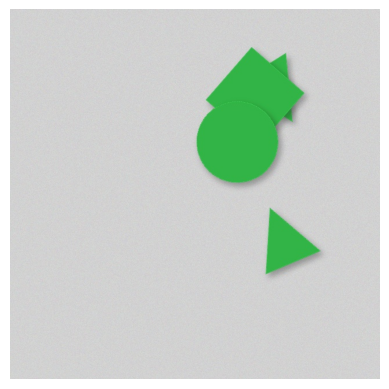

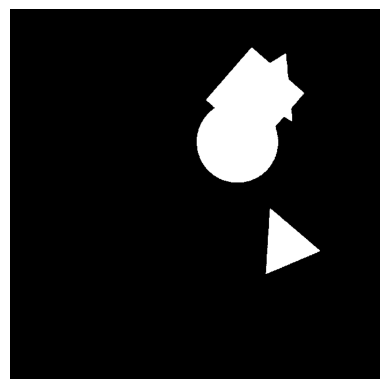

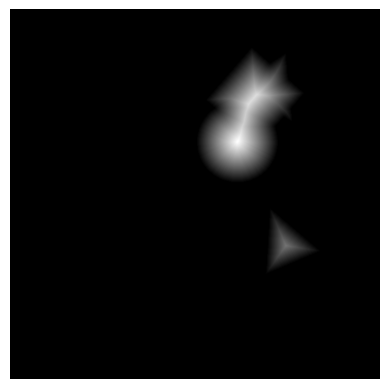

In [19]:
image = cv.imread(r"C:\Users\Omar-PC\OneDrive - El Sewedy Education\Desktop\shape_color_sorting\Dataset\images\train\synthetic_1.jpg")
print(image.shape)

plt.imshow(cv.cvtColor(image, cv.COLOR_BGR2RGB))
plt.axis("off")
plt.show()
image_hsv = cv.cvtColor(image, cv.COLOR_BGR2HSV)

lower_green = np.array([35, 100, 20])
upper_green = np.array([85, 255, 255])

mask_green = cv.inRange(image_hsv, lower_green, upper_green)

plt.imshow(mask_green, cmap="gray")
plt.axis("off")
plt.show()
distance = cv.distanceTransform(
    mask_green,
    cv.DIST_L2,
    5
)

plt.imshow(distance, cmap="gray")
plt.axis("off")
plt.show()

Maximum distance: 69.50388


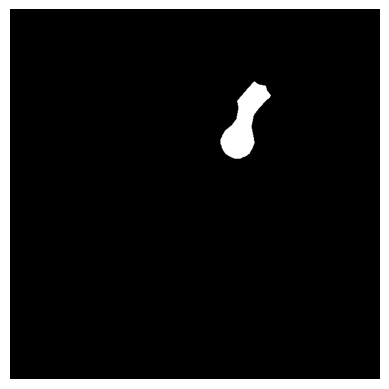

Connected foreground regions: 1


In [22]:
max_distance = distance.max()

print("Maximum distance:", max_distance)

_, sure_fg = cv.threshold(
    distance,
    0.6 * max_distance,
    255,
    cv.THRESH_BINARY
)

sure_fg = np.uint8(sure_fg)

plt.imshow(sure_fg, cmap="gray")
plt.axis("off")
plt.show()
num_labels, labels = cv.connectedComponents(sure_fg)

print("Connected foreground regions:", num_labels - 1)


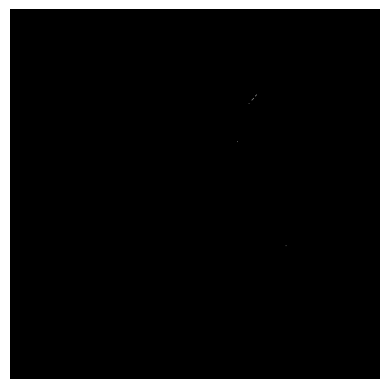

In [26]:
kernel = np.ones((25, 25), np.uint8)
dilated_distance = cv.dilate(distance, kernel)

local_max = (
    (distance == dilated_distance)
    & (distance > 0.25 * max_distance)
)

peak_mask = np.uint8(local_max) * 255

plt.imshow(peak_mask, cmap="gray")
plt.axis("off")
plt.show()

In [28]:
num_peaks, peak_labels, stats, centroids = cv.connectedComponentsWithStats(peak_mask)

for i in range(1, num_peaks):   # skip background
    print(f"Peak {i}: {centroids[i]}")
print("Number of peak regions:", num_peaks - 1)

Peak 1: [425. 149.]
Peak 2: [419.5 155.5]
Peak 3: [413. 163.]
Peak 4: [393. 229.]
Peak 5: [477. 409.]
Number of peak regions: 5


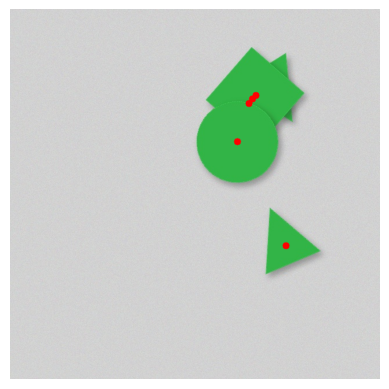

In [29]:
peak_image = image.copy()

for i in range(1, num_peaks):
    cx, cy = centroids[i]

    cv.circle(
        peak_image,
        (int(cx), int(cy)),
        6,
        (0, 0, 255),
        -1
    )

plt.imshow(cv.cvtColor(peak_image, cv.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

### Observation

Using a global distance-transform threshold did not successfully
separate the overlapping objects. At a high threshold, smaller
objects may also disappear.